- **Гипотеза 3.** На сколько можно увеличить прибыль предлагая перейти на тариф member.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

- читаю файл "../../../data_after_preprocessing/drd_with_weather.parquet"

In [2]:
drd_with_weather = pd.read_parquet('../../../data_after_preprocessing/drd_with_weather.parquet')
drd_with_weather

,rideable_type,start_station_name,start_station_id,end_station_name,end_station_id,started_at,ended_at,member_casual,date,temp,feelslike,humidity,dew,visibility,windspeed,precipcover,snow,icon,duration_in_minutes
0,docked_bike,Anacostia Library,31804,11th & H St NE,31614,2020-05-30 17:25:29.000,2020-05-31 18:25:22.000,casual,2020-05-30,24.299999,24.100000,55.700001,13.800000,16.0,32.700001,4.17,0.0,rain,1499.883301
1,docked_bike,10th & E St NW,31256,21st St & Constitution Ave NW,31261,2020-05-09 14:42:04.000,2020-05-09 15:06:33.000,member,2020-05-09,6.800000,3.600000,41.900002,-5.700000,16.0,40.799999,0.00,0.0,partly-cloudy-day,24.483334
2,docked_bike,Connecticut Ave & Newark St NW / Cleveland Park,31305,12th & U St NW,31268,2020-05-24 17:27:19.000,2020-05-24 17:43:51.000,member,2020-05-24,18.000000,18.000000,82.300003,14.900000,15.8,20.900000,0.00,0.0,cloudy,16.533333
3,docked_bike,Connecticut Ave & Newark St NW / Cleveland Park,31305,14th & Belmont St NW,31119,2020-05-27 15:29:52.000,2020-05-27 15:47:13.000,casual,2020-05-27,22.200001,22.200001,79.199997,18.200001,15.8,17.500000,0.00,0.0,partly-cloudy-day,17.350000
4,docked_bike,Georgia Ave & Morton St NW,31419,17th & K St NW,31213,2020-05-31 14:06:03.000,2020-05-31 14:30:30.000,casual,2020-05-31,20.400000,20.400000,39.500000,6.000000,16.0,28.500000,0.00,0.0,partly-cloudy-day,24.450001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16086667,electric_bike,NaN,0,NaN,0,2024-08-01 08:10:22.293,2024-08-01 08:10:37.641,member,2024-08-01,29.600000,31.900000,64.500000,21.600000,15.9,17.100000,0.00,0.0,partly-cloudy-day,0.255800
16086668,electric_bike,NaN,0,NaN,0,2024-08-08 10:05:21.938,2024-08-08 10:21:46.654,member,2024-08-08,25.900000,26.200001,86.000000,23.400000,13.6,20.000000,50.00,0.0,rain,16.411934
16086669,electric_bike,NaN,0,NaN,0,2024-08-03 16:29:32.252,2024-08-03 16:35:43.179,member,2024-08-03,27.900000,30.000000,71.099998,21.900000,15.7,34.599998,12.50,0.0,rain,6.182117
16086670,electric_bike,NaN,0,NaN,0,2024-08-03 02:49:45.661,2024-08-03 02:59:56.877,member,2024-08-03,27.900000,30.000000,71.099998,21.900000,15.7,34.599998,12.50,0.0,rain,10.186934


- убираю docked_bike из dataframe

In [3]:
drd_with_weather = drd_with_weather[drd_with_weather['rideable_type'] != 'docked_bike']

- смотрю занимаемую долю member и casual

In [4]:
(drd_with_weather['member_casual'].value_counts() / len(drd_with_weather)) * 100

member_casual
member    63.923537
casual    36.076463
Name: count, dtype: float64

- сортирую данные по столбцу date

In [5]:
drd_with_weather = drd_with_weather.sort_values(by='date', ascending=True)

- добавляю новый столбец year

In [6]:
drd_with_weather['year'] = drd_with_weather['started_at'].dt.year

- делаю группировку по столбцам year и member_casual и считаю для каждого количество поездок

In [7]:
yearly_users = drd_with_weather.groupby(['year', 'member_casual']).size().reset_index(name='rides')
yearly_users

,year,member_casual,rides
0,2020,casual,144259
1,2020,member,143277
2,2021,casual,915248
3,2021,member,1633099
4,2022,casual,1206843
5,2022,member,2045021
6,2023,casual,1539361
7,2023,member,2813905
8,2024,casual,1327742
9,2024,member,2460614


- строю график количество поездок по годам

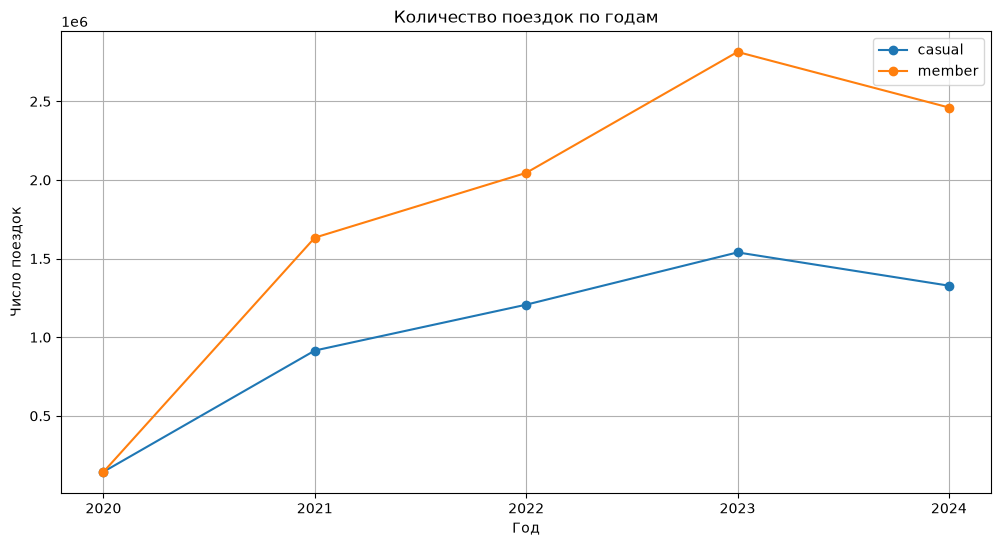

In [8]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    yearly_users[yearly_users['member_casual'] == 'casual']['year'],
    yearly_users[yearly_users['member_casual'] == 'casual']['rides'],
    marker='o',
    label='casual'
)

ax.plot(
    yearly_users[yearly_users['member_casual'] == 'member']['year'],
    yearly_users[yearly_users['member_casual'] == 'member']['rides'],
    marker='o',
    label='member'
)

ax.legend()
ax.set_xticks(yearly_users['year'].unique())

plt.title('Количество поездок по годам')
plt.ylabel('Число поездок')
plt.xlabel('Год')
plt.grid(True)

plt.show()

- считаю занимаемую долю member и casual

In [9]:
yearly_users['share_pct'] = yearly_users['rides'] / yearly_users.groupby('year')['rides'].transform('sum') * 100

- вывожу результат

In [10]:
yearly_users

,year,member_casual,rides,share_pct
0,2020,casual,144259,50.170761
1,2020,member,143277,49.829239
2,2021,casual,915248,35.915360
3,2021,member,1633099,64.084640
4,2022,casual,1206843,37.112345
5,2022,member,2045021,62.887655
6,2023,casual,1539361,35.361060
7,2023,member,2813905,64.638940
8,2024,casual,1327742,35.047973
9,2024,member,2460614,64.952027


- строю график занимаемая доля поездок по годам

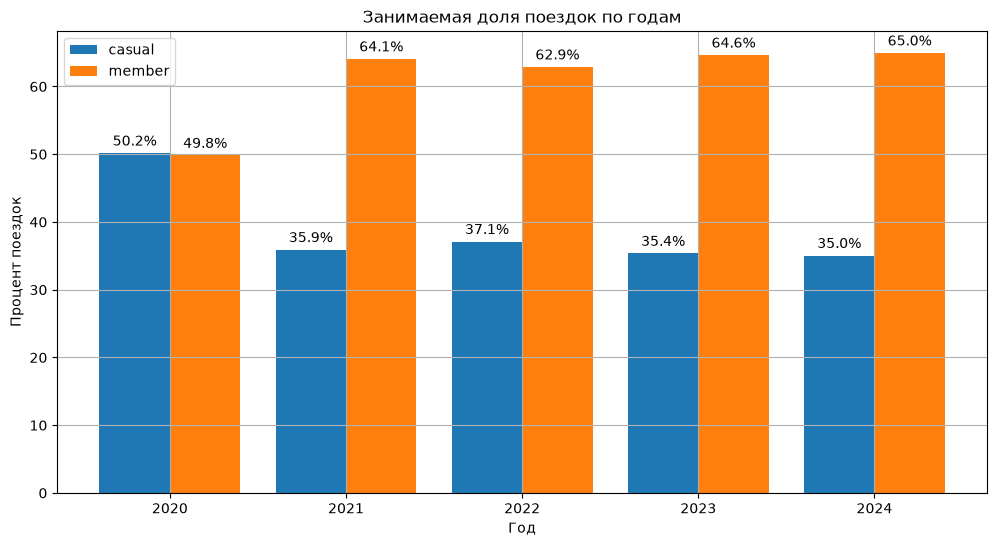

In [18]:
fig, ax = plt.subplots(figsize=(12, 6))

width = 0.4

bars_casual = ax.bar(
    yearly_users[yearly_users['member_casual'] == 'casual']['year'] - width / 2,
    yearly_users[yearly_users['member_casual'] == 'casual']['share_pct'],
    width=width,
    label='casual',
)

bars_member = ax.bar(
    yearly_users[yearly_users['member_casual'] == 'member']['year'] + width / 2,
    yearly_users[yearly_users['member_casual'] == 'member']['share_pct'],
    width=width,
    label='member'
)

ax.bar_label(bars_casual, fmt='%.1f%%', padding=3)
ax.bar_label(bars_member, fmt='%.1f%%', padding=3)

ax.legend()
ax.set_xticks(yearly_users['year'].unique())

plt.title('Занимаемая доля поездок по годам')
plt.ylabel('Процент поездок')
plt.xlabel('Год')
plt.grid(True)


plt.show()

- группирую данные по member_casual и считаю медиану аренды

In [20]:
drd_with_weather.groupby('member_casual')['duration_in_minutes'].median()

member_casual
casual    14.180667
member     9.327933
Name: duration_in_minutes, dtype: float32

- добавляю новый столбец day_name

In [21]:
drd_with_weather['day_name'] = drd_with_weather['started_at'].dt.day_name()

- делаю группировку по столбцам member_casual и day_name и считаю сколько раз брали велосипед в аренду

In [23]:
ride_of_day_name = drd_with_weather.groupby(['member_casual', 'day_name'])['duration_in_minutes'].count().reset_index()

- делаю pivot

In [25]:
ride_of_day_name = ride_of_day_name.pivot(columns='day_name', index='member_casual', values='duration_in_minutes')
ride_of_day_name

day_name,Friday,Monday,Saturday,Sunday,Thursday,Tuesday,Wednesday
member_casual,,,,,,,
casual,744750,609975,983991,841910,676885,631749,644193
member,1316135,1243449,1209655,1084783,1409583,1403671,1428640


- устанавливаю столбцы в правильном порядке с понедельника по воскресенье

In [26]:
ride_of_day_name = ride_of_day_name.set_axis(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'], axis=1)

<Axes: xlabel='member_casual'>

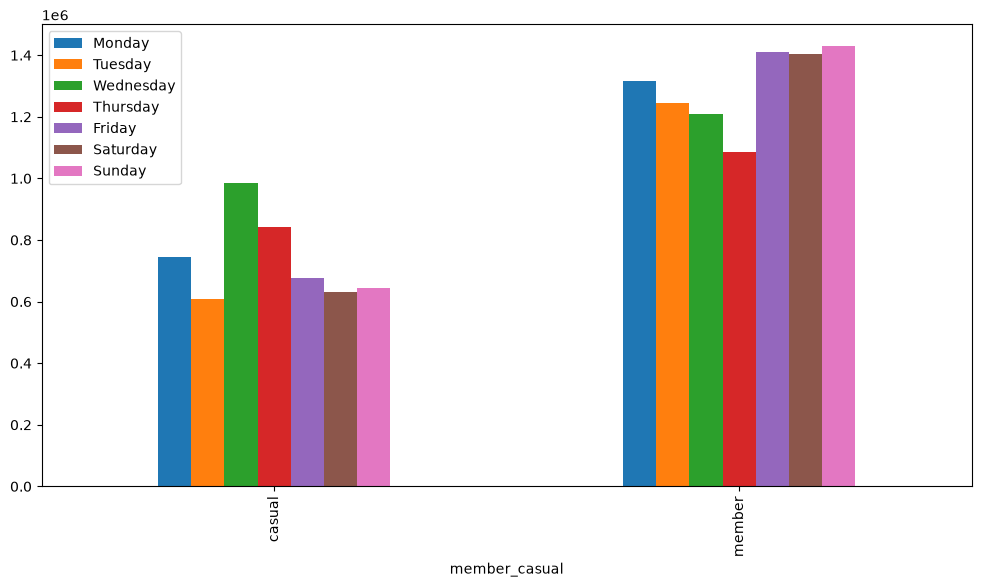

In [28]:
ride_of_day_name.plot(kind='bar', figsize=(12, 6))

- делаю группировку по столбцам 'year', 'member_casual', 'day_name' и считаю сумму по столбцу 'duration_in_minutes'

In [40]:
ride_of_year_day_name = drd_with_weather.groupby(['year', 'member_casual', 'day_name'])['duration_in_minutes'].sum().reset_index()
ride_of_year_day_name

,year,member_casual,day_name,duration_in_minutes
0,2020,casual,Friday,4.914010e+05
1,2020,casual,Monday,3.557301e+05
2,2020,casual,Saturday,7.183146e+05
3,2020,casual,Sunday,5.958456e+05
4,2020,casual,Thursday,3.843662e+05
...,...,...,...,...
65,2024,member,Saturday,4.184792e+06
66,2024,member,Sunday,3.900141e+06
67,2024,member,Thursday,4.854544e+06
68,2024,member,Tuesday,4.738097e+06


- подготавливаю данные для того что бы вывести их на график

In [41]:
ride_of_year_day_name = ride_of_year_day_name.pivot(columns=['year', 'day_name'], index='member_casual', values='duration_in_minutes')
ride_of_year_day_name

year                   2020                                         \
day_name             Friday        Monday    Saturday       Sunday   
member_casual                                                        
casual         491401.03125  355730.06250  718314.625  595845.6250   
member         365677.34375  294889.96875  440270.125  380984.8125   

year                                                           2021  \
day_name           Thursday       Tuesday     Wednesday      Friday   
member_casual                                                         
casual         384366.21875  388235.53125  395144.28125  3606308.00   
member         316962.93750  332155.31250  320541.09375  3340658.25   

year                                  ...       2023                        \
day_name           Monday   Saturday  ...   Thursday    Tuesday  Wednesday   
member_casual                         ...                                    
casual         2990484.75  6450980.5  ...  5101348.0  4747006.0  4740498.5   
member         3018905.75  3820185.5  ...  5974327.5  5910838.0  6122758.0   

year                2024                                                \
day_name          Friday     Monday    Saturday      Sunday   Thursday   
member_casual                                                            
casual         4765627.5  3837794.5  6717939.00  6199200.50  4240258.0   
member         4516490.0  4298910.5  4184791.75  3900141.25  4854544.5   

year                                 
day_name         Tuesday  Wednesday  
member_casual                        
casual         3797928.0  3765391.5  
member         4738097.0  4785909.5  

[2 rows x 35 columns]

- строю график по годам и каждому дню недели

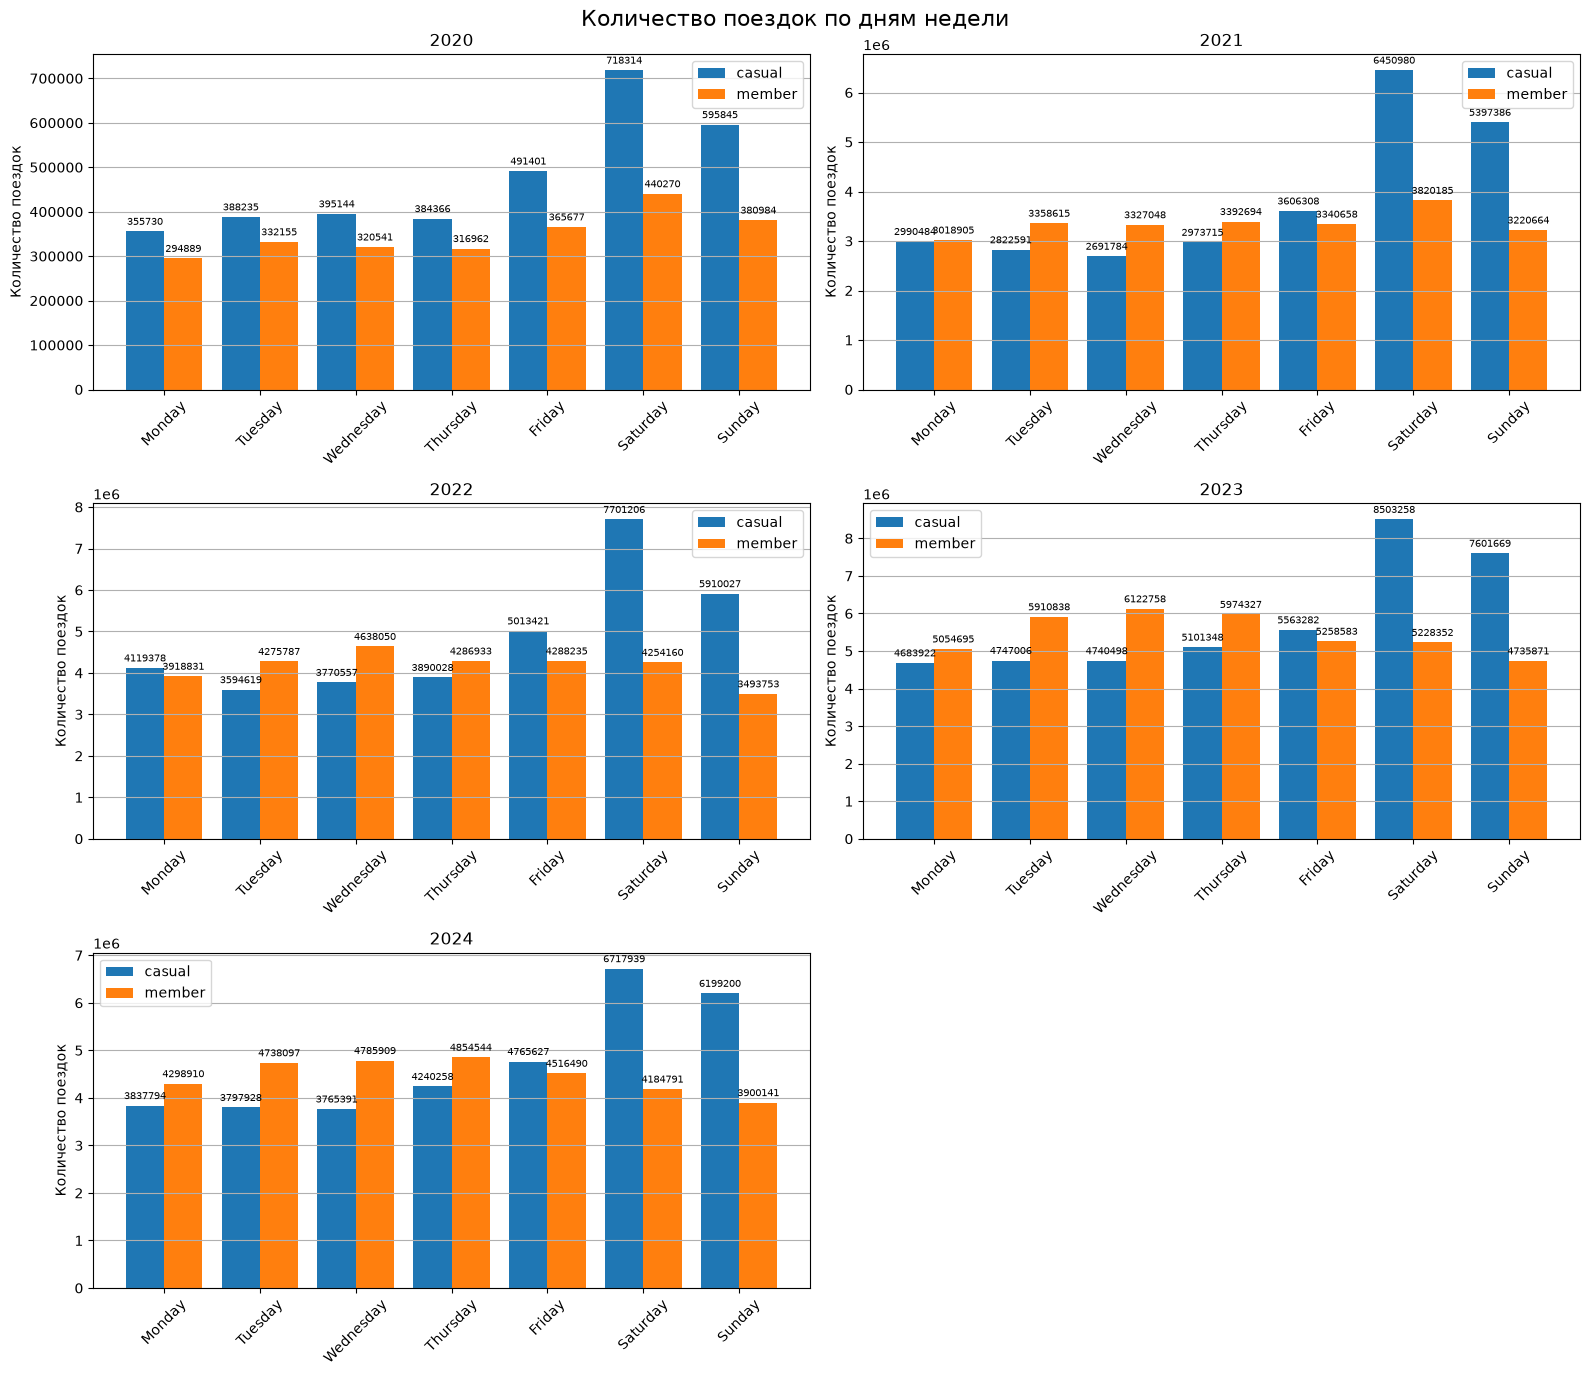

In [43]:
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
years = ride_of_year_day_name.columns.get_level_values('year').unique()

fig, axes = plt.subplots(3, 2, figsize=(16, 14))
axes = axes.flatten()

width = 0.4
x = np.arange(len(days_order))

for ax, year in zip(axes, years):
    data = ride_of_year_day_name[year].reindex(columns=days_order)  # правильный порядок дней

    bars_casual = ax.bar(
        x - width / 2,
        data.loc['casual'],
        width=width,
        label='casual',
    )

    bars_member = ax.bar(
        x + width / 2,
        data.loc['member'],
        width=width,
        label='member',
    )

    ax.bar_label(bars_casual, fmt='%d', padding=3, fontsize=7)
    ax.bar_label(bars_member, fmt='%d', padding=3, fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(days_order, rotation=45)
    ax.set_title(f'{year}')
    ax.set_ylabel('Количество поездок')
    ax.legend()
    ax.grid(True, axis='y')

# убираем пустые оси, если годов меньше 6
for ax in axes[len(years):]:
    ax.set_visible(False)

fig.suptitle('Количество поездок по дням недели', fontsize=16)
plt.tight_layout()
plt.show()

- вывожу таблицу занимаемой доли classic_bike и electric_bike у casual и member

In [44]:
pd.crosstab(drd_with_weather['rideable_type'], drd_with_weather['member_casual'], normalize='columns')

member_casual,casual,member
rideable_type,,
classic_bike,0.658679,0.685199
electric_bike,0.341321,0.314801


In [46]:
ride_a_bike_less_45 = drd_with_weather[drd_with_weather['duration_in_minutes'] < 45]
ride_a_bike_less_45

,rideable_type,start_station_name,start_station_id,end_station_name,end_station_id,started_at,ended_at,member_casual,date,temp,...,humidity,dew,visibility,windspeed,precipcover,snow,icon,duration_in_minutes,year,day_name
180175,electric_bike,Carroll & Westmoreland Ave,32025,Takoma Metro,31408,2020-06-17 16:14:39.000,2020-06-17 16:17:03.000,member,2020-06-17,20.0,...,81.099998,16.600000,14.0,27.600000,37.5,0.0,rain,2.400000,2020,Wednesday
281588,electric_bike,3rd & Underwood St NW,31413,NaN,0,2020-06-17 14:49:02.000,2020-06-17 14:51:47.000,member,2020-06-17,20.0,...,81.099998,16.600000,14.0,27.600000,37.5,0.0,rain,2.750000,2020,Wednesday
281571,electric_bike,3rd & Underwood St NW,31413,NaN,0,2020-06-17 14:46:55.000,2020-06-17 14:51:56.000,casual,2020-06-17,20.0,...,81.099998,16.600000,14.0,27.600000,37.5,0.0,rain,5.016667,2020,Wednesday
276814,electric_bike,NaN,0,Carroll & Westmoreland Ave,32025,2020-06-17 16:07:20.000,2020-06-17 16:13:20.000,member,2020-06-17,20.0,...,81.099998,16.600000,14.0,27.600000,37.5,0.0,rain,6.000000,2020,Wednesday
246717,electric_bike,3rd & Underwood St NW,31413,3rd & Underwood St NW,31413,2020-06-17 14:42:06.000,2020-06-17 14:42:13.000,member,2020-06-17,20.0,...,81.099998,16.600000,14.0,27.600000,37.5,0.0,rain,0.116667,2020,Wednesday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15555512,electric_bike,NaN,0,16th & Irving St NW,31122,2024-08-31 09:57:59.623,2024-08-31 10:01:35.159,member,2024-08-31,24.1,...,80.099998,20.299999,15.8,17.200001,12.5,0.0,rain,3.592267,2024,Saturday
15894889,classic_bike,Eastern Market / 7th & North Carolina Ave SE,31610,10th St & L'Enfant Plaza SW,31287,2024-08-31 10:31:43.375,2024-08-31 10:59:19.302,casual,2024-08-31,24.1,...,80.099998,20.299999,15.8,17.200001,12.5,0.0,rain,27.598783,2024,Saturday
15709641,electric_bike,12th St & Pennsylvania Ave SE,31644,11th & C St SE,31659,2024-08-31 18:12:46.803,2024-08-31 18:14:54.950,member,2024-08-31,24.1,...,80.099998,20.299999,15.8,17.200001,12.5,0.0,rain,2.135783,2024,Saturday
15857651,electric_bike,Potomac Ave & 8th St SE,31635,1st St & Potomac Ave SE,31668,2024-08-31 19:03:32.404,2024-08-31 19:12:59.772,casual,2024-08-31,24.1,...,80.099998,20.299999,15.8,17.200001,12.5,0.0,rain,9.456133,2024,Saturday


In [48]:
count_cost = ride_a_bike_less_45.groupby(['rideable_type', 'member_casual'])['duration_in_minutes'].agg(['count', 'median'])

- вывожу результат

In [49]:
count_cost

count     median
rideable_type member_casual                    
classic_bike  casual         2918302  13.750000
              member         6120035   9.133333
electric_bike casual         1637076  10.783334
              member         2786284   9.166667

- посмотрел стоимость в интернете

- Casual
    - classic_bike
        - взять 1 доллар и далее 0.15 минута
    - электрик байк
        - 0.15 доллара

- Member
    - classic_bike
        - 10 долларов за 45 минут (Day Pass)
    - электрик байк
        - 0.15 доллара (Day Pass)
        - 25 месяц


### Вывод по гипотезе 9 - На сколько можно увеличить прибыль предлагая перейти на тариф member.

- Исходя из анализа я получил следующее:
    - casual пользователи примерно делают столько же поездок (в минутах), сколько и member 
    - активность пользователей casual смещается на выходные и преобладает над member в 1,5-1,8 раза
    - в будние дни member опережает casual (разрыв не большой)

- Не никаго смысла переводить на тариф member если пользователь casual
- Можно подумать над тарифом на выходные, так как пользователи casual становится больше в выходные